In [1]:
import xarray as xr, numpy as np, pandas as pd
import matplotlib.pyplot as plt, cartopy.crs as ccrs
import matplotlib.cm as cm, matplotlib.colors as mcolors
from matplotlib.patches import Patch
import cartopy.feature as cfeature

from functions import build_country_weights, verify_population_coverage, EU_MEMBERS,\
                        country_weights_dict, baseline_start, baseline_end, lat_to_str_dict, \
                        cider_inj_lats_popweighted, basepath, cpath, cider_combined, pop, \
                        countries_zip_path, select_eu_mode, reorient_netcdf

In [2]:
n_members = 500
newpath = basepath + f'{n_members}_members/' 

ssp_plus_invert = xr.open_dataset(newpath + 
                    f'SSP370_plus_InVERT_{n_members}member_ensemble_TREFHT_2015_to_2065.nc')

baseline = ssp_plus_invert.sel(time=slice(baseline_start, baseline_end))

In [3]:
#### Values of sensitivity-tested parameters
buffer_months = 12
tau = 12
eval_months = 36

### Where results are saved for this set of parameters
rpath = newpath + \
        f'results_buffer={buffer_months}m_tau={tau}m_eval={eval_months}m_k_2050/'
print(rpath)

k_setting = 'country_k'

/home/msaenger/Perceptions_2025/cleaned_code/500_members/results_buffer=12m_tau=12m_eval=36m_k_2050/


In [4]:
## Folded country polygons (labels match country_da/W_norm_eu exactly) 
countries = country_weights_dict['countries_gdf']

## Sanity check that every grid cell's population is accounted for in the country rows
verify_population_coverage(country_weights_dict)

PASSED -- Population coverage: 100.000000% (8.016736e+09 of 8.016736e+09 people-equivalent) accounted for across kept country rows.


{'population_total': 8016736089.992069,
 'population_accounted': 8016736089.992069,
 'coverage_frac': 1.0,
 'passed': True}

In [5]:
## Load min injection rate datasets computed in 05_find_min_injection_rate_..._.py

inj_rates_single_lat = xr.open_dataset(rpath + f'single_lat_min_rates_{k_setting}.nc')
inj_rates_uniform = xr.open_dataset(rpath + f'global_uniform_min_rates_{k_setting}.nc')

In [6]:
## Filter EU countries according to the chosen eu_mode

eu_mode = 'aggregated'

inj_rates_single_lat = select_eu_mode(inj_rates_single_lat, eu_mode)
inj_rates_uniform = select_eu_mode(inj_rates_uniform, eu_mode)

## Manually set all NaNs (e.g. where 250 Tg/yr was not enough to keep f below threshold) to 250 

In [7]:
def replace_nans(ds, val=250):
    
    return ds.where(~np.isnan(ds), val)

In [8]:
inj_rates_single_lat_nans_replaced = replace_nans(inj_rates_single_lat)
inj_rates_single_lat_nans_replaced.to_netcdf(rpath + \
                            f'single_lat_min_rates_{k_setting}_EU_agg_nans_replaced.nc')

In [9]:
inj_rates_uniform_nans_replaced = replace_nans(inj_rates_uniform)
inj_rates_uniform_nans_replaced.to_netcdf(rpath + \
                            f'global_uniform_min_rates_{k_setting}_EU_agg_nans_replaced.nc')

In [10]:
pctile = 0.9

nans_replaced = inj_rates_single_lat_nans_replaced.min_injection_rate.quantile(pctile, 
                                            dim='ensemble', method='higher', skipna=True) 
original = inj_rates_single_lat.min_injection_rate.quantile(pctile,
                                            dim='ensemble', method='higher', skipna=True)
test_diff = nans_replaced - original

print('Difference after replacing NaN with 250:')
for country in test_diff.country.values:
    if int(test_diff.sel(country=country).values) > 0:
        print(country, int(test_diff.sel(country=country).values))

Difference after replacing NaN with 250:
Brazil 1
China 1
European Union 14
India 3
Pakistan 1
Russia 12
United Kingdom 242


In [11]:
nans_replaced = inj_rates_uniform_nans_replaced.min_injection_rate.quantile(pctile, 
                                            dim='ensemble', method='higher', skipna=True) 
original = inj_rates_uniform.min_injection_rate.quantile(pctile, 
                                            dim='ensemble', method='higher', skipna=True)
test_diff = nans_replaced - original

print('Difference after replacing NaN with 250:')
for country in test_diff.country.values:
    if int(test_diff.sel(country=country).values) > 0:
        print(country, int(test_diff.sel(country=country).values))

Difference after replacing NaN with 250:
Australia 1
Brazil 2
China 1
European Union 14
India 2
Russia 14
United Kingdom 240
United States of America 1


In [12]:
def plot_inj_rate_maps(inj_rate_ds, injection_type, pctile, eu_mode, vmax=None,
                       ax=None, add_colorbar=True, eu_label='European Union'):
    """
    Plot a choropleth of the Nth percentile SO2 injection rate by deploying country.

    If `ax` is given, the map is drawn onto that (already-projected) axes instead of creating
    its own figure -- this lets the map be dropped into a multi-panel figure so that the 
    single-lat and uniform strategies can share one figure and one colorbar. If `ax` is None, 
    a standalone figure is created and shown, matching the original standalone behavior.

    Returns the ScalarMappable used for the colorbar
    """
    ## Compute percentile injection rate for each country across its ensemble
    pctile_injection_rate = inj_rate_ds.min_injection_rate.quantile(pctile,
                                    dim='ensemble', method='higher', skipna=True)

    ## Check how many ensemble members are 'valid' for each percentile computation
    n_valid = inj_rate_ds.min_injection_rate.notnull().sum(dim='ensemble').values
    print(n_valid)
    
    # Lookup table: country name -> selected percentile value (NaN if not in the dataset)
    pctile_lookup = dict(zip(pctile_injection_rate.country.values,
                             pctile_injection_rate.values))
    vmin = 0
    if vmax is None:
        vmax = np.nanmax(pctile_injection_rate.values)
    cmap = plt.cm.YlOrRd
    norm = mcolors.Normalize(vmin=vmin, vmax=vmax)

    standalone = ax is None
    if standalone:
        fig, ax = plt.subplots(figsize=(12, 6), subplot_kw={'projection': ccrs.Robinson()})
    ax.set_global()
    ax.set_facecolor('white')   # anything not covered by a country polygon (i.e. ocean)

    for _, row in countries.iterrows():
        name = row['ADMIN']
        if eu_mode == 'aggregated':
            eu_value = pctile_lookup.get(eu_label, np.nan) 
            value = eu_value if name in EU_MEMBERS else pctile_lookup.get(name, np.nan)
        else:
            value = pctile_lookup.get(name, np.nan)
        facecolor = 'lightgray' if np.isnan(value) else cmap(norm(value))
        ax.add_geometries([row['geometry']], crs=ccrs.PlateCarree(),
                           facecolor=facecolor, edgecolor='dimgray', linewidth=0.2)
    ax.coastlines(linewidth=0.3)
    sm = cm.ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])
    if add_colorbar:
        cbar = plt.colorbar(sm, ax=ax, orientation='horizontal', pad=0.05, shrink=0.5)
        cbar.set_label('$SO_{2}$ injection rate ($Tg yr^{-1}$)')
    ax.set_title(
        f'{injection_type} injection', fontsize=20)
#     if standalone:
#         plt.suptitle(f'{n_members} member ensemble')
#         plt.tight_layout()

    return sm, pctile_injection_rate

In [13]:
def plot_inj_rate_maps_comparison(inj_rates_single_lat, inj_rates_uniform,
                                  pctile, eu_mode, vmax=None, pinatubo_rate=18.5):
    """
    Plot the single-latitude and globally-uniform injection rate maps side by side in one figure, 
    sharing one colorbar. vmax defaults to the higher of the two strategies' Nth-percentile 
    injection rates, so both maps use the same color scale.
    """
    injection_types = [('single latitude', inj_rates_single_lat),
                        ('globally uniform', inj_rates_uniform)]
    if vmax is None:
        vmax_candidates = []
        for _, ds in injection_types:
            pctile_vals = ds.min_injection_rate.quantile(pctile, 
                                        dim='ensemble', method='higher', skipna=True)
            vmax_candidates.append(np.nanmax(pctile_vals.values))
        vmax = max(vmax_candidates)

    fig, axes = plt.subplots(1, 2, figsize=(16, 6),
                              subplot_kw={'projection': ccrs.Robinson()})
    mappable = None
    
    panel_labels = ['(a)', '(b)']
    
    inj_rates_dict = {}
    
    for ax, (injection_type, ds), panel_label in zip(axes, injection_types, panel_labels):
        mappable, inj_rates = plot_inj_rate_maps(ds, injection_type, pctile, eu_mode,
                                      vmax=vmax, ax=ax, add_colorbar=False)
        
        inj_rates_dict[injection_type] = inj_rates
        
        ax.text(0.02, 1.06, panel_label, transform=ax.transAxes,
                fontsize=18, fontweight='bold', va='top', ha='left',
                zorder=10)

    fig.subplots_adjust(bottom=0.15)
    cbar_ax = fig.add_axes([0.25, 0.06, 0.5, 0.04])  # [left, bottom, width, height]
    cbar = fig.colorbar(mappable, cax=cbar_ax, orientation='horizontal')
    cbar.set_label('$SO_{2}$ injection rate $(Tg yr^{-1})$', fontsize=16)
    cbar_ax.tick_params(labelsize=14)
    
    # ---- Mt Pinatubo reference marker ----
    if pinatubo_rate is not None and mappable.norm.vmin <= pinatubo_rate <= mappable.norm.vmax:
        # x in data units (the colorbar's value axis), y in axes fraction (1.0 = top edge of bar)
        trans = cbar_ax.get_xaxis_transform()
        cbar_ax.plot(pinatubo_rate, 0.9, marker='v', color='black', markersize=9,
                     transform=trans, clip_on=False, zorder=5)
        cbar_ax.text(pinatubo_rate, 1.5, f'Mt Pinatubo (~{pinatubo_rate} Tg)', transform=trans,
                     ha='center', va='bottom', fontsize=16)
    # --------------------------------------
    
#     plt.suptitle(f'{int(pctile*100)}th percentile injection rates',## {k_setting}', 
#                  fontsize=24, y=0.96)
    plt.tight_layout()
    
    plt.savefig(rpath + f'inj_rate_map_{int(pctile*100)}th_pctile_{k_setting}_EU_{eu_mode}_2050.pdf',
                bbox_inches='tight')
    plt.savefig(rpath + f'inj_rate_map_{int(pctile*100)}th_pctile_{k_setting}_EU_{eu_mode}_2050.png',
                bbox_inches='tight')
    
    return inj_rates_dict

[500 500 500 500 500 500 500 500 500 500 500 500 500 500 500 500 500]
[500 500 500 500 500 500 500 500 500 500 500 500 500 500 500 500 500]
Australia 11.0
Bangladesh 10.0
Brazil 20.0
China 6.0
Egypt 7.0
Ethiopia 14.0
European Union 30.0
India 14.0
Indonesia 11.0
Japan 5.0
Nigeria 18.0
Pakistan 7.0
Russia 24.0
Saudi Arabia 6.0
South Africa 13.0
United Kingdom 250.0
United States of America 6.0
/n
Australia 21.0
Bangladesh 14.0
Brazil 22.0
China 12.0
Egypt 15.0
Ethiopia 15.0
European Union 32.0
India 15.0
Indonesia 14.0
Japan 11.0
Nigeria 19.0
Pakistan 11.0
Russia 29.0
Saudi Arabia 11.0
South Africa 19.0
United Kingdom 250.0
United States of America 13.0


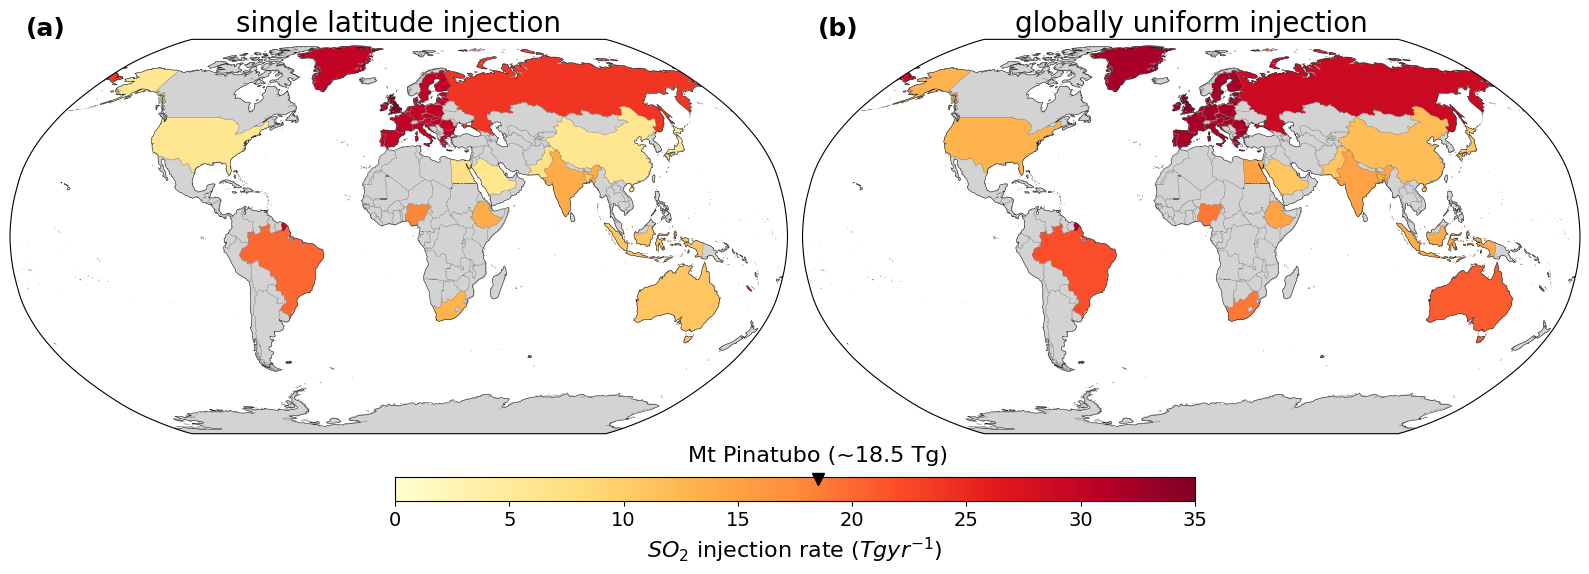

In [32]:
pctile = .9

result_dict = plot_inj_rate_maps_comparison(inj_rates_single_lat_nans_replaced, 
                              inj_rates_uniform_nans_replaced, 
                              pctile, eu_mode, vmax=35)

for country in result_dict['single latitude'].country.values:
    print(country, result_dict['single latitude'].sel(country=country).values)
    
print('/n')
    
for country in result_dict['globally uniform'].country.values:
    print(country, result_dict['globally uniform'].sel(country=country).values)

In [16]:
for country in result_dict['globally uniform'].country.values:
    
    print(country, result_dict['globally uniform'].sel(country=country).values)

Australia 21.0
Bangladesh 14.0
Brazil 22.0
China 12.0
Egypt 15.0
Ethiopia 15.0
European Union 32.0
India 15.0
Indonesia 14.0
Japan 11.0
Nigeria 19.0
Pakistan 11.0
Russia 29.0
Saudi Arabia 11.0
South Africa 19.0
United Kingdom 250.0
United States of America 13.0


[500 500 500 500 500 500 500 500 500 500 500 500 500 500 500 500 500]
[500 500 500 500 500 500 500 500 500 500 500 500 500 500 500 500 500]
Australia 15.0
Bangladesh 16.0
Brazil 33.0
China 8.0
Egypt 9.0
Ethiopia 18.0
European Union 250.0
India 25.0
Indonesia 15.0
Japan 6.0
Nigeria 24.0
Pakistan 9.0
Russia 250.0
Saudi Arabia 8.0
South Africa 19.0
United Kingdom 250.0
United States of America 10.0
Australia 28.0
Bangladesh 20.0
Brazil 31.0
China 17.0
Egypt 19.0
Ethiopia 21.0
European Union 250.0
India 27.0
Indonesia 20.0
Japan 15.0
Nigeria 25.0
Pakistan 17.0
Russia 250.0
Saudi Arabia 16.0
South Africa 26.0
United Kingdom 250.0
United States of America 21.0


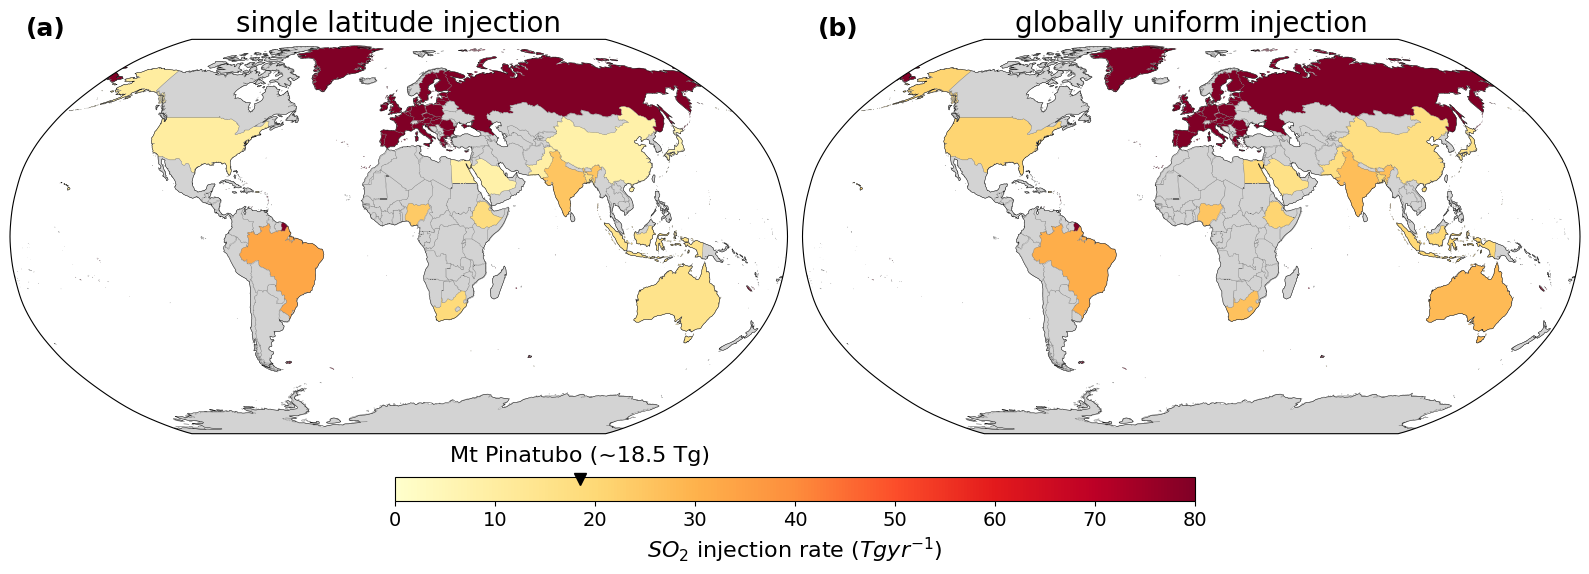

In [22]:
pctile = .95

result_dict = plot_inj_rate_maps_comparison(inj_rates_single_lat_nans_replaced, 
                              inj_rates_uniform_nans_replaced, 
                              pctile, eu_mode, vmax=80)

for country in result_dict['single latitude'].country.values:
    
    print(country, result_dict['single latitude'].sel(country=country).values)
    
for country in result_dict['globally uniform'].country.values:
    
    print(country, result_dict['globally uniform'].sel(country=country).values)

[500 500 500 500 500 500 500 500 500 500 500 500 500 500 500 500 500]
[500 500 500 500 500 500 500 500 500 500 500 500 500 500 500 500 500]
Australia 250.0
Bangladesh 54.0
Brazil 250.0
China 250.0
Egypt 28.0
Ethiopia 95.0
European Union 250.0
India 250.0
Indonesia 54.0
Japan 250.0
Nigeria 64.0
Pakistan 250.0
Russia 250.0
Saudi Arabia 17.0
South Africa 153.0
United Kingdom 250.0
United States of America 250.0
/n
Australia 250.0
Bangladesh 62.0
Brazil 250.0
China 250.0
Egypt 54.0
Ethiopia 55.0
European Union 250.0
India 250.0
Indonesia 62.0
Japan 250.0
Nigeria 54.0
Pakistan 250.0
Russia 250.0
Saudi Arabia 33.0
South Africa 81.0
United Kingdom 250.0
United States of America 250.0


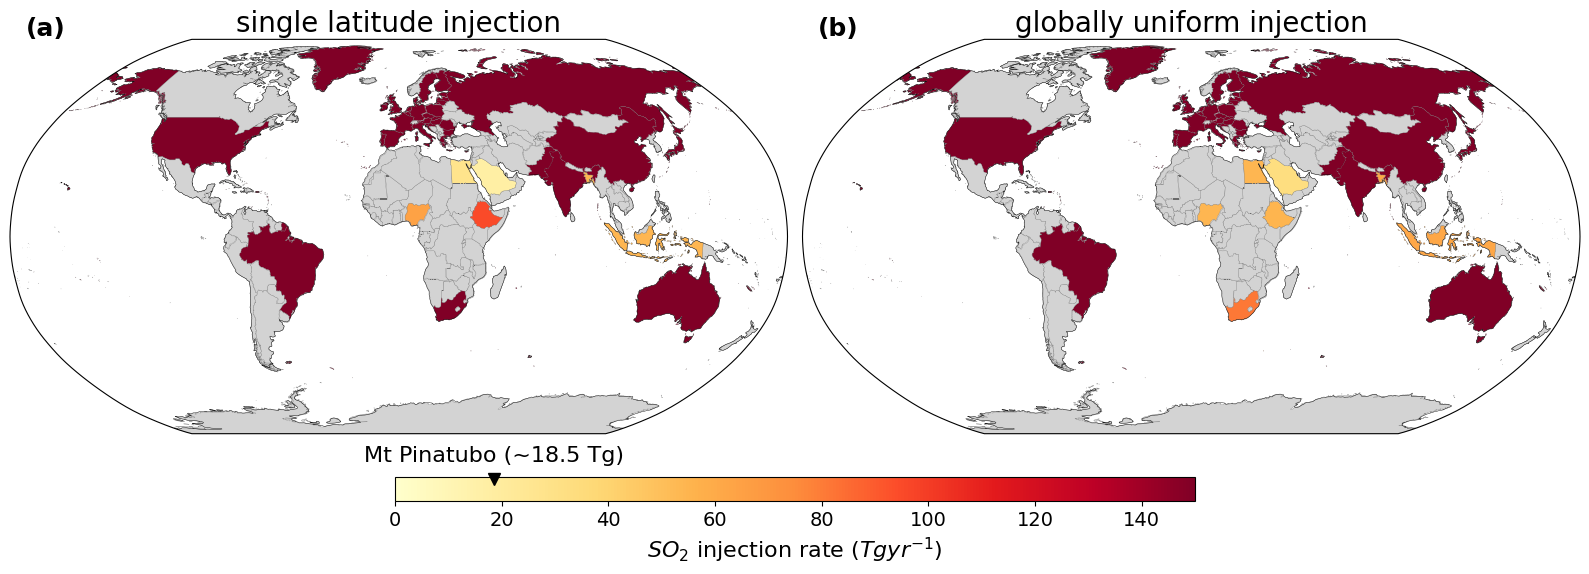

In [23]:
pctile = 1.0

result_dict = plot_inj_rate_maps_comparison(inj_rates_single_lat_nans_replaced, 
                              inj_rates_uniform_nans_replaced, 
                              pctile, eu_mode, vmax=150)

for country in result_dict['single latitude'].country.values:
    print(country, result_dict['single latitude'].sel(country=country).values)
    
print('/n')
    
for country in result_dict['globally uniform'].country.values:
    print(country, result_dict['globally uniform'].sel(country=country).values)